# EDA — Medical Insurance Cost Prediction
**Role:** Sooryajith K — Data Exploration

Goal: understand the dataset before anyone builds a model on it. We'll check what's in the data, look at distributions, compare groups, and write up what we find.

## 1. Setup — import libraries
`pandas` reads and manipulates the data. `matplotlib`/`seaborn` make the charts.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Makes charts a decent size and readable by default
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)

## 2. Load the data
Make sure `insurance.csv` is inside your project's `/data` folder (download it from the Kaggle "Medical Cost Personal Dataset" page if you haven't).

In [2]:
df = pd.read_csv('../data/insurance.csv')

# Quick look at the first few rows
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 3. First checks: shape, types, missing values

- `.info()` tells you column names, data types, and how many non-null values each has
- `.describe()` gives summary stats (mean, min, max, etc.) for numeric columns
- `.isnull().sum()` counts missing values per column — ideally all zeros

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [5]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [6]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

**What I Found:** No missing values across any of the 1,338 rows — every column has a complete count. Data types are appropriate: `age`/`bmi`/`children`/`charges` are numeric, while `sex`/`smoker`/`region` are categorical text fields. This means the dataset is clean and ready for preprocessing without needing to handle missing data.

## 4. Histograms — shape of the numeric columns

A histogram shows how values are spread out. We care about `age`, `bmi`, and `charges` specifically. Watch for **skew** — a lopsided distribution with a long tail on one side.

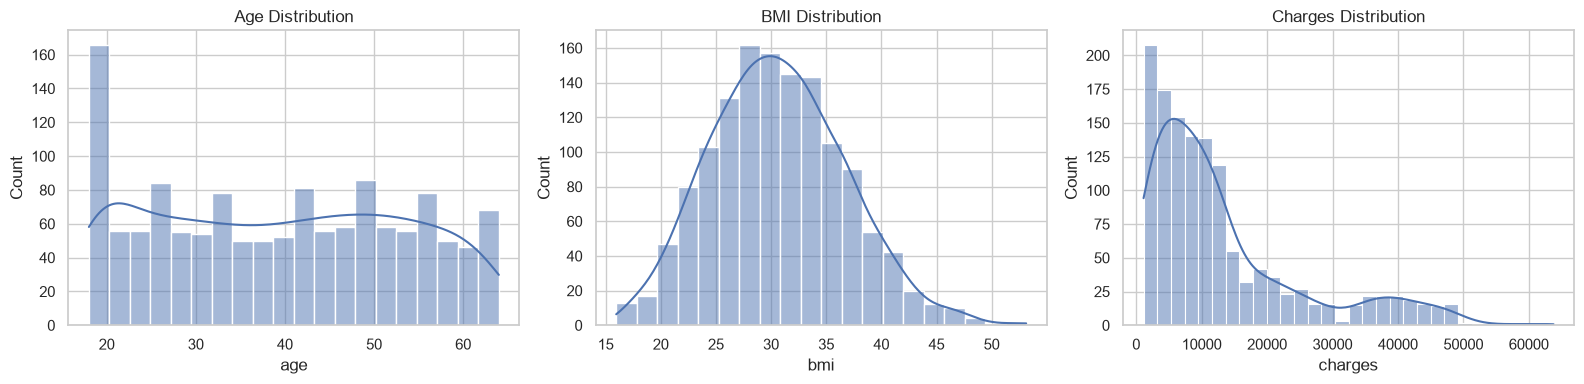

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df['age'], bins=20, kde=True, ax=axes[0])
axes[0].set_title('Age Distribution')

sns.histplot(df['bmi'], bins=20, kde=True, ax=axes[1])
axes[1].set_title('BMI Distribution')

sns.histplot(df['charges'], bins=30, kde=True, ax=axes[2])
axes[2].set_title('Charges Distribution')

plt.tight_layout()
plt.show()

**What I Observered:** Looking at the three distributions: the age histogram shows a large spike at the youngest age (18–19), then levels off fairly evenly across the 20–60 range — this dataset isn't randomly sampled by age, it's slightly weighted toward younger individuals. BMI follows a roughly normal (bell-shaped) distribution centered around 30, with a mild right tail toward higher BMI values (40+). Charges is the most skewed of the three: most individuals are clustered under $15,000, but there's a long tail stretching out to over $60,000. Notably, there's a small secondary bump in the charges distribution around $35,000–$45,000, separate from the main cluster — this hints that the population isn't uniform, and (as the later boxplot confirms) this second group corresponds to smokers.

## 5. Boxplots — does `charges` differ by group?

A boxplot shows the spread (median, quartiles, outliers) of a numeric column, split by category. This is where we start hunting for patterns that matter for the model later.

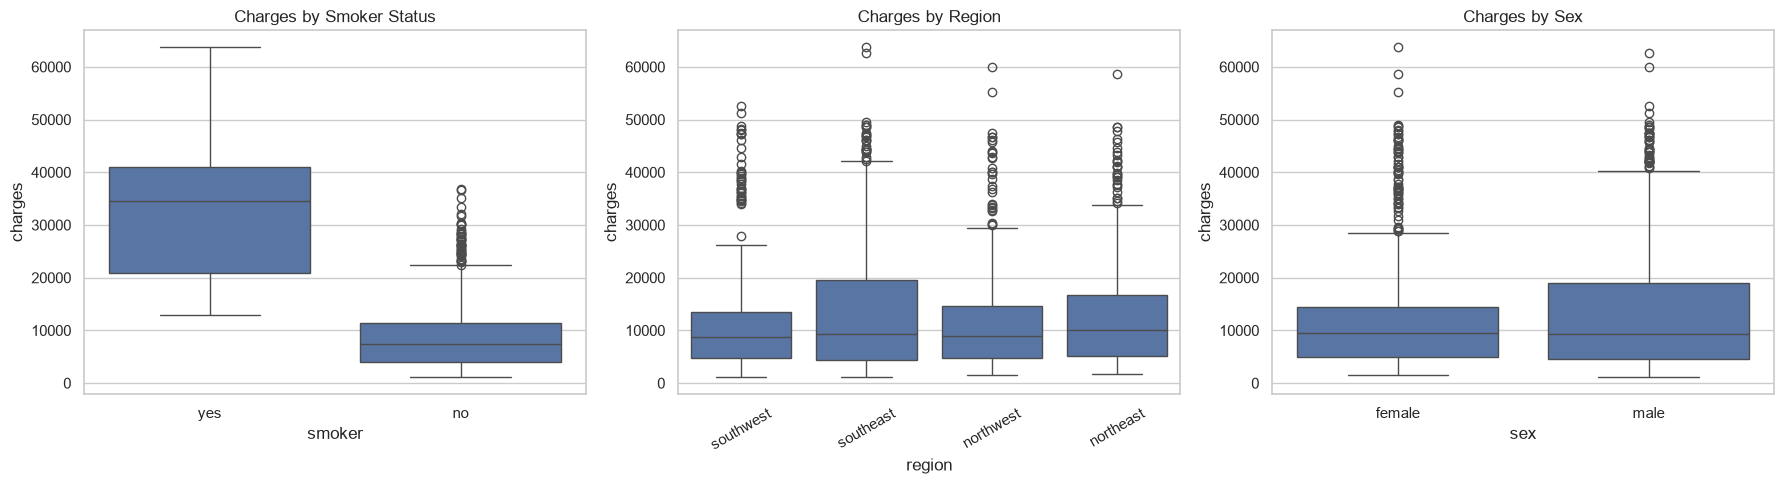

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=df, x='smoker', y='charges', ax=axes[0])
axes[0].set_title('Charges by Smoker Status')

sns.boxplot(data=df, x='region', y='charges', ax=axes[1])
axes[1].set_title('Charges by Region')
axes[1].tick_params(axis='x', rotation=30)

sns.boxplot(data=df, x='sex', y='charges', ax=axes[2])
axes[2].set_title('Charges by Sex')

plt.tight_layout()
plt.show()

**What I Observered:** Smokers show a dramatically higher spread than non-smokers: their median charge sits around $34,000, compared to roughly $8,000 for non-smokers — even the lowest-charged smokers pay more than the median non-smoker. Non-smokers have many individual outlier points above their box (likely older individuals or those with high BMI, since smoking alone isn't driving their cost). By comparison, region and sex show far smaller differences: median charges across all four regions sit in a fairly narrow $8,000–$10,000 range, with southeast marginally higher, and male vs. female medians are nearly identical. This confirms smoking status is by far the dominant factor in cost among the variables checked here

## 6. Correlation heatmap

Correlation tells us how strongly two numeric columns move together, from -1 (perfectly opposite) to +1 (perfectly together). Since `smoker` is text (yes/no), we encode it as 0/1 first so it can be included — this is a preview of what Tanishq will do properly in preprocessing.

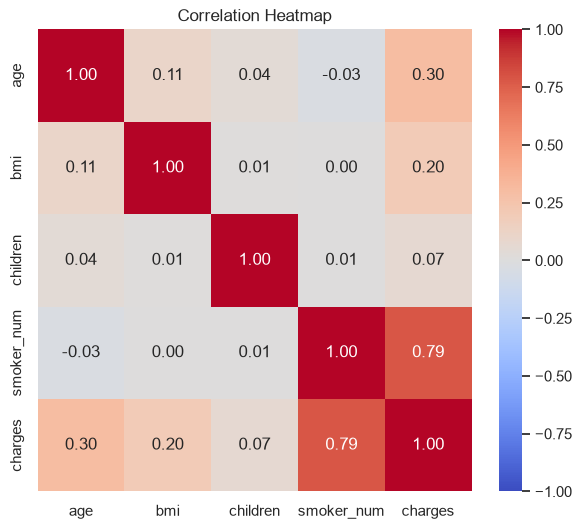

In [8]:
# Temporary encoding just for this correlation check (Tanishq does the 'real' encoding later)
df_corr = df.copy()
df_corr['smoker_num'] = df_corr['smoker'].map({'yes': 1, 'no': 0})

numeric_cols = ['age', 'bmi', 'children', 'smoker_num', 'charges']
corr_matrix = df_corr[numeric_cols].corr()

plt.figure(figsize=(7, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Correlation Heatmap')
plt.show()

**What I found:** `smoker_num` has by far the strongest correlation with charges at 0.79, confirming smoking status as the single biggest driver of cost. `age` shows a moderate positive correlation (0.30), `bmi` is weaker (0.20), and `children` is essentially uncorrelated (0.07). Interestingly, `smoker_num` itself has almost no correlation with age, bmi, or children (all near 0) — meaning smokers aren't a systematically older, heavier, or larger-family group. Its effect on charges is independent of these other factors, which makes it an especially strong and "clean" predictor for the modeling stage.

## 7. Key findings
The dataset is complete with no missing values across all 1,338 records. Charges are heavily right-skewed — the mean ($13,270) is well above the median ($9,382), driven by a smaller group of high-cost individuals. Smoking status is by far the strongest driver of cost: smokers have a median charge of roughly $34,000 versus about $8,000 for non-smokers (a ~4x difference), and this shows up clearly in both the boxplot and the correlation heatmap (r = 0.79 with charges — the highest of any variable). Age has a moderate positive relationship with charges (r = 0.30), while BMI is weaker (r = 0.20), and region/sex/children show little to no meaningful effect on cost.

